In [ ]:
# Module 7: Carbon Footprint / Sustainability Score

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

print("Carbon Footprint / Sustainability Score")
print("----------------------------------------")
print("Libraries loaded successfully!")

Carbon Footprint / Sustainability Score
----------------------------------------
Libraries loaded successfully!


In [ ]:
import pandas as pd

# Load agricultural dataset
url = "https://raw.githubusercontent.com/Aswins10/Agricultural-Crop-Yield-in-Indian-States-Dataset/main/crop_yield.csv"

carbon_df = pd.read_csv(url)

print("Dataset shape:", carbon_df.shape)

print("\nColumns:")
print(carbon_df.columns.tolist())

print("\nFirst 5 rows:")
display(carbon_df.head())

Dataset shape: (19689, 10)

Columns:
['Crop', 'Crop_Year', 'Season', 'State', 'Area', 'Production', 'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Yield']

First 5 rows:


,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,2051.4,7024878.38,22882.34,0.796087
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,2051.4,631643.29,2057.47,0.710435
2,Castor seed,1997,Kharif,Assam,796.0,22,2051.4,75755.32,246.76,0.238333
3,Coconut,1997,Whole Year,Assam,19656.0,126905000,2051.4,1870661.52,6093.36,5238.051739
4,Cotton(lint),1997,Kharif,Assam,1739.0,794,2051.4,165500.63,539.09,0.420909


In [ ]:
# Clean the dataset

carbon_df = carbon_df.copy()

numeric_cols = [
    "Area",
    "Production",
    "Annual_Rainfall",
    "Fertilizer",
    "Pesticide",
    "Yield"
]

for col in numeric_cols:
    carbon_df[col] = pd.to_numeric(
        carbon_df[col],
        errors="coerce"
    )

# Remove invalid/missing values
carbon_df = carbon_df.dropna(
    subset=[
        "Crop",
        "State",
        "Area",
        "Production",
        "Fertilizer",
        "Pesticide",
        "Yield"
    ]
).copy()

# Avoid division by zero
carbon_df = carbon_df[
    (carbon_df["Area"] > 0) &
    (carbon_df["Production"] > 0)
].copy()

# Calculate resource intensity per hectare
carbon_df["Fertilizer_per_Ha"] = (
    carbon_df["Fertilizer"] / carbon_df["Area"]
)

carbon_df["Pesticide_per_Ha"] = (
    carbon_df["Pesticide"] / carbon_df["Area"]
)

# Production efficiency
carbon_df["Production_per_Ha"] = (
    carbon_df["Production"] / carbon_df["Area"]
)

print("Cleaned dataset shape:", carbon_df.shape)

print("\nNew sustainability indicators:")
print([
    "Fertilizer_per_Ha",
    "Pesticide_per_Ha",
    "Production_per_Ha"
])

display(
    carbon_df[
        [
            "Crop",
            "State",
            "Area",
            "Fertilizer_per_Ha",
            "Pesticide_per_Ha",
            "Production_per_Ha",
            "Yield"
        ]
    ].head()
)

Cleaned dataset shape: (19577, 13)

New sustainability indicators:
['Fertilizer_per_Ha', 'Pesticide_per_Ha', 'Production_per_Ha']


,Crop,State,Area,Fertilizer_per_Ha,Pesticide_per_Ha,Production_per_Ha,Yield
0,Arecanut,Assam,73814.0,95.17,0.31,0.768255,0.796087
1,Arhar/Tur,Assam,6637.0,95.17,0.31,0.705891,0.710435
2,Castor seed,Assam,796.0,95.17,0.31,0.027638,0.238333
3,Coconut,Assam,19656.0,95.17,0.31,6456.298331,5238.051739
4,Cotton(lint),Assam,1739.0,95.17,0.31,0.456584,0.420909


In [ ]:
# Calculate normalized sustainability indicators

# Lower fertilizer and pesticide intensity = better
fert_score = 100 * (
    1 - (
        (carbon_df["Fertilizer_per_Ha"] -
         carbon_df["Fertilizer_per_Ha"].min())
        /
        (
            carbon_df["Fertilizer_per_Ha"].max() -
            carbon_df["Fertilizer_per_Ha"].min()
        )
    )
)

pest_score = 100 * (
    1 - (
        (carbon_df["Pesticide_per_Ha"] -
         carbon_df["Pesticide_per_Ha"].min())
        /
        (
            carbon_df["Pesticide_per_Ha"].max() -
            carbon_df["Pesticide_per_Ha"].min()
        )
    )
)

# Higher production efficiency = better
efficiency_score = 100 * (
    (carbon_df["Production_per_Ha"] -
     carbon_df["Production_per_Ha"].min())
    /
    (
        carbon_df["Production_per_Ha"].max() -
        carbon_df["Production_per_Ha"].min()
    )
)

# Combined Sustainability Score
carbon_df["Sustainability_Score"] = (
    0.35 * fert_score +
    0.30 * pest_score +
    0.35 * efficiency_score
)

# Keep score within 0-100
carbon_df["Sustainability_Score"] = carbon_df[
    "Sustainability_Score"
].clip(0, 100)

print("Sustainability Score calculated successfully!")

display(
    carbon_df[
        [
            "Crop",
            "State",
            "Fertilizer_per_Ha",
            "Pesticide_per_Ha",
            "Production_per_Ha",
            "Sustainability_Score"
        ]
    ].head(10)
)

print("\nScore statistics:")
print(carbon_df["Sustainability_Score"].describe())

Sustainability Score calculated successfully!


,Crop,State,Fertilizer_per_Ha,Pesticide_per_Ha,Production_per_Ha,Sustainability_Score
0,Arecanut,Assam,95.17,0.31,0.768255,42.065775
1,Arhar/Tur,Assam,95.17,0.31,0.705891,42.065671
2,Castor seed,Assam,95.17,0.31,0.027638,42.064546
3,Coconut,Assam,95.17,0.31,6456.298331,52.771464
4,Cotton(lint),Assam,95.17,0.31,0.456584,42.065258
5,Dry chillies,Assam,95.17,0.31,0.667771,42.065608
6,Gram,Assam,95.17,0.31,0.505874,42.065339
7,Jute,Assam,95.17,0.31,9.565118,42.080363
8,Linseed,Assam,95.17,0.31,0.510794,42.065348
9,Maize,Assam,95.17,0.31,0.766080,42.065771



Score statistics:
count    19577.000000
mean        31.062578
std         14.147745
min          1.034920
25%         17.385770
50%         35.092643
75%         44.070887
max         72.335828
Name: Sustainability_Score, dtype: float64


In [ ]:
# Categorize sustainability scores

def sustainability_category(score):
    if score >= 60:
        return "High Sustainability"
    elif score >= 30:
        return "Moderate Sustainability"
    else:
        return "Low Sustainability"

carbon_df["Sustainability_Category"] = (
    carbon_df["Sustainability_Score"]
    .apply(sustainability_category)
)

print("Sustainability category distribution:")
print(
    carbon_df["Sustainability_Category"]
    .value_counts()
)

print("\nCategory percentages:")
print(
    carbon_df["Sustainability_Category"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

display(
    carbon_df[
        [
            "Crop",
            "State",
            "Sustainability_Score",
            "Sustainability_Category"
        ]
    ].head(15)
)


Sustainability category distribution:
Sustainability_Category
Moderate Sustainability    9788
Low Sustainability         9752
High Sustainability          37
Name: count, dtype: int64

Category percentages:
Sustainability_Category
Moderate Sustainability    50.00
Low Sustainability         49.81
High Sustainability         0.19
Name: proportion, dtype: float64


,Crop,State,Sustainability_Score,Sustainability_Category
0,Arecanut,Assam,42.065775,Moderate Sustainability
1,Arhar/Tur,Assam,42.065671,Moderate Sustainability
2,Castor seed,Assam,42.064546,Moderate Sustainability
3,Coconut,Assam,52.771464,Moderate Sustainability
4,Cotton(lint),Assam,42.065258,Moderate Sustainability
5,Dry chillies,Assam,42.065608,Moderate Sustainability
6,Gram,Assam,42.065339,Moderate Sustainability
7,Jute,Assam,42.080363,Moderate Sustainability
8,Linseed,Assam,42.065348,Moderate Sustainability
9,Maize,Assam,42.065771,Moderate Sustainability


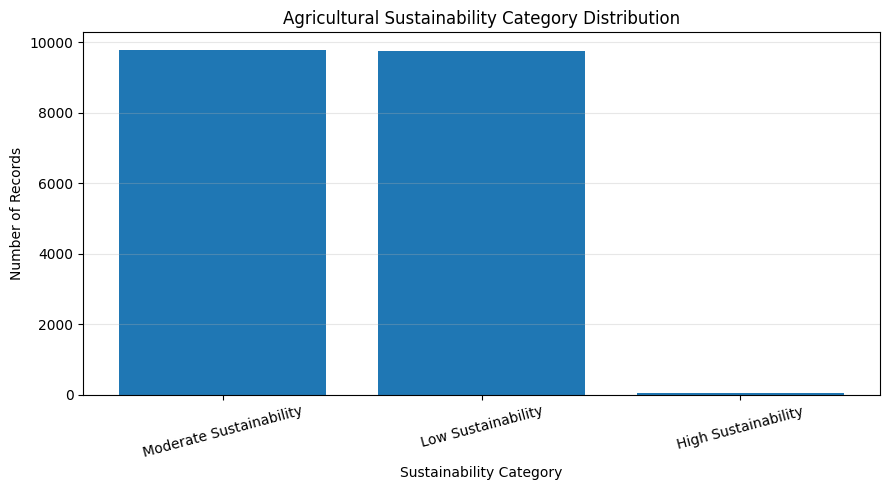

Top 15 crops by average Sustainability Score:


,Sustainability_Score
Crop,
Coconut,47.738457
Cardamom,34.433777
Sannhamp,33.559689
Sugarcane,32.595469
Banana,32.318261
Linseed,32.303387
Jute,32.142893
Arecanut,32.097030
Dry chillies,32.084579


In [ ]:
# Sustainability category visualization

category_counts = (
    carbon_df["Sustainability_Category"]
    .value_counts()
)

plt.figure(figsize=(9, 5))

plt.bar(
    category_counts.index,
    category_counts.values
)

plt.xlabel("Sustainability Category")
plt.ylabel("Number of Records")
plt.title("Agricultural Sustainability Category Distribution")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# Average sustainability score by crop
crop_scores = (
    carbon_df.groupby("Crop")["Sustainability_Score"]
    .mean()
    .sort_values(ascending=False)
)

print("Top 15 crops by average Sustainability Score:")
display(crop_scores.head(15))

In [ ]:
# Create reusable Sustainability Score calculator

# Save normalization ranges from the training dataset
sustainability_config = {
    "fertilizer_min": float(carbon_df["Fertilizer_per_Ha"].min()),
    "fertilizer_max": float(carbon_df["Fertilizer_per_Ha"].max()),
    "pesticide_min": float(carbon_df["Pesticide_per_Ha"].min()),
    "pesticide_max": float(carbon_df["Pesticide_per_Ha"].max()),
    "production_min": float(carbon_df["Production_per_Ha"].min()),
    "production_max": float(carbon_df["Production_per_Ha"].max()),
    "fertilizer_weight": 0.35,
    "pesticide_weight": 0.30,
    "production_weight": 0.35
}

def calculate_sustainability_score(
    fertilizer_per_ha,
    pesticide_per_ha,
    production_per_ha
):
    # Fertilizer score: lower is better
    fert_range = (
        sustainability_config["fertilizer_max"]
        - sustainability_config["fertilizer_min"]
    )

    fert_score = 100 * (
        1 - (
            (fertilizer_per_ha -
             sustainability_config["fertilizer_min"])
            / fert_range
        )
    )

    # Pesticide score: lower is better
    pest_range = (
        sustainability_config["pesticide_max"]
        - sustainability_config["pesticide_min"]
    )

    pest_score = 100 * (
        1 - (
            (pesticide_per_ha -
             sustainability_config["pesticide_min"])
            / pest_range
        )
    )

    # Production efficiency: higher is better
    production_range = (
        sustainability_config["production_max"]
        - sustainability_config["production_min"]
    )

    efficiency_score = 100 * (
        (production_per_ha -
         sustainability_config["production_min"])
        / production_range
    )

    # Weighted score
    score = (
        sustainability_config["fertilizer_weight"] * fert_score +
        sustainability_config["pesticide_weight"] * pest_score +
        sustainability_config["production_weight"] * efficiency_score
    )

    score = float(np.clip(score, 0, 100))

    # Category
    if score >= 60:
        category = "High Sustainability"
    elif score >= 30:
        category = "Moderate Sustainability"
    else:
        category = "Low Sustainability"

    return score, category


# Test calculator using first record
test_row = carbon_df.iloc[0]

test_score, test_category = calculate_sustainability_score(
    test_row["Fertilizer_per_Ha"],
    test_row["Pesticide_per_Ha"],
    test_row["Production_per_Ha"]
)

print("Sustainability Calculator Test")
print("--------------------------------")
print(f"Score    : {test_score:.2f}/100")
print(f"Category : {test_category}")


Sustainability Calculator Test
--------------------------------
Score    : 42.07/100
Category : Moderate Sustainability


In [ ]:
from google.colab import drive
import os

# Mount Google Drive
drive.mount("/content/drive")

# Make sure MyDrive exists
print("Drive mounted:", os.path.exists("/content/drive/MyDrive"))

Mounted at /content/drive
Drive mounted: True


In [ ]:
# Save Carbon Footprint / Sustainability Score module

save_dir = "/content/drive/MyDrive"

# Save sustainability configuration
joblib.dump(
    sustainability_config,
    f"{save_dir}/sustainability_score_config.pkl"
)

# Save sustainability results
carbon_df.to_csv(
    f"{save_dir}/sustainability_score_results.csv",
    index=False
)

# Save crop-wise average scores
crop_scores.to_csv(
    f"{save_dir}/crop_sustainability_scores.csv"
)

# Save module information
sustainability_model_info = {
    "module": "Carbon Footprint / Sustainability Score",
    "score_range": "0-100",
    "fertilizer_weight": 0.35,
    "pesticide_weight": 0.30,
    "production_efficiency_weight": 0.35,
    "high_sustainability_threshold": 60,
    "moderate_sustainability_threshold": 30,
    "low_sustainability_threshold": 0,
    "note": (
        "This is a model-based sustainability index. "
        "The dataset does not contain direct CO2 emission measurements, "
        "so the score should not be interpreted as an actual carbon footprint."
    )
}

joblib.dump(
    sustainability_model_info,
    f"{save_dir}/sustainability_model_info.pkl"
)

print("Carbon Footprint / Sustainability Score saved successfully!")

print("\nSaved files:")
print("✓ sustainability_score_config.pkl")
print("✓ sustainability_score_results.csv")
print("✓ crop_sustainability_scores.csv")
print("✓ sustainability_model_info.pkl")

Carbon Footprint / Sustainability Score saved successfully!

Saved files:
✓ sustainability_score_config.pkl
✓ sustainability_score_results.csv
✓ crop_sustainability_scores.csv
✓ sustainability_model_info.pkl
